# Cracked vs. Non-cracked Surface Classification: CNN with a Pretrained Model (ResNet50)

**Approach:** transfer learning. We take ResNet50 trained on ImageNet, replace its last layer with a 2-class head, and fine-tune it.

**How this notebook avoids retraining for the person who downloads it:**
- Every experiment saves its results to `results/<name>.json` (history + train/test accuracy). If that file exists, the experiment is **skipped** and the saved results are loaded instead (`FORCE_RETRAIN = False`).
- The best model is saved to `final_model/resnet50_best.pt`. The last section **loads it and evaluates it with no training**.

**Run order:** run all cells top to bottom. The experiment section is the slow one (hours on a 4 GB GPU).

## 1. Setup

Imports, a fixed random seed (so every run and every teammate gets the same split), and device selection.
`!pip install` is only needed once (on Colab most of these already exist).

In [1]:
# !pip install -q kagglehub torch torchvision scikit-learn pandas matplotlib seaborn pillow tqdm

import os, json, time, random, copy
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm.auto import tqdm

import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

SEED = 42                      # same seed for the whole team => same split => comparable results
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed()

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)
if device == "cuda":
    print("GPU:", torch.cuda.get_device_name(0),
          f"| VRAM: {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB")

# Folders where everything is saved
os.makedirs("results", exist_ok=True)      # per-experiment json (+ checkpoints)
os.makedirs("final_model", exist_ok=True)  # the best model, to share
os.makedirs("plots", exist_ok=True)

Device: cuda
GPU: Quadro T2000 | VRAM: 4.3 GB


## 2. Global settings

Things you may want to change in one place.
- `FORCE_RETRAIN=False` means "if a result already exists, don't retrain" (this is what lets others skip training).
- `MAX_PER_CLASS` can limit images per class to make experiments faster (set `None` to use everything).
- `IMG_SIZE=224` is the standard ResNet50 input size.

In [2]:

IMG_SIZE = 224
NUM_WORKERS = 0            # if you get DataLoader errors on Windows, set this to 0
FORCE_RETRAIN = False      # True = ignore saved results and retrain everything
MAX_PER_CLASS = None       # e.g. 5000 to speed things up; None = use all images
IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
CLASS_NAMES = ["Non-cracked", "Cracked"]   # label 0 and label 1

# Part I: Data Preparation

## 3. Download and load the data

`kagglehub` downloads the dataset and gives back the local folder. The Kaggle page does not clearly document the folder layout, so the next cell **finds all images automatically** and derives the label from the folder names (a folder with "non"/"no"/"negative"... in its name means *Non-cracked*, otherwise *Cracked*). **Check the printed table** to make sure the mapping is correct.

In [3]:
DATA_ROOT = r"D:\nn data\Bangunan Retak"
print("Dataset folder:", DATA_ROOT)

Dataset folder: D:\nn data\Bangunan Retak


In [4]:
IMG_EXT = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff")
NEG_WORDS = ("non", "no_", "no-", "negative", "uncrack", "without", "neg", "normal", "good")

def label_from_path(rel_path):
    # Looks at the folder names only (not the filename); checks "non-cracked" words first,
    # because "non-cracked" also contains the word "cracked".
    folders = os.path.dirname(rel_path).lower()
    if any(w in folders for w in NEG_WORDS):
        return 0
    return 1

rows = []
for dirpath, _, files in os.walk(DATA_ROOT):
    for f in files:
        if f.lower().endswith(IMG_EXT):
            rel = os.path.relpath(os.path.join(dirpath, f), DATA_ROOT)   # relative path => works on any computer
            rows.append({"path": rel, "label": label_from_path(rel), "folder": os.path.dirname(rel)})

df = pd.DataFrame(rows)
print("Total images found:", len(df))

# VERIFY the mapping: every folder should map to one sensible label
print(df.groupby(["folder", "label"]).size().rename("n_images"))

Total images found: 96092
folder       label
Cracked      1        28484
Non Cracked  0        67608
Name: n_images, dtype: int64


> **Check the table above.** If a folder is mapped to the wrong label, edit `NEG_WORDS` or set the labels by hand, e.g. `df["label"] = df["folder"].apply(lambda f: 0 if "YOUR_NEG_FOLDER" in f else 1)`.

In [5]:
# Optional: limit images per class for faster experiments
if MAX_PER_CLASS:
    df = (df.groupby("label", group_keys=False)
            .apply(lambda g: g.sample(min(len(g), MAX_PER_CLASS), random_state=SEED))
            .reset_index(drop=True))
    print("Using a subset:", len(df))

## 4. Describe the data

Number of images, class balance, and image sizes/modes. Class imbalance matters because plain accuracy can look good even if the model ignores the minority class; we handle it later with class weights and by also reporting precision/recall/F1.

In [6]:
counts = df["label"].value_counts().sort_index()
print("Total images:", len(df))
for k, v in counts.items():
    print(f"  {CLASS_NAMES[k]:12s}: {v:6d}  ({100*v/len(df):.1f}%)")
print("Imbalance ratio (majority/minority): %.2f" % (counts.max()/counts.min()))

# Inspect image sizes and color modes on a random sample (reading all images would be slow)
sample = df.sample(min(300, len(df)), random_state=SEED)
sizes, modes = [], []
for p in sample["path"]:
    with Image.open(os.path.join(DATA_ROOT, p)) as im:
        sizes.append(im.size); modes.append(im.mode)
print("\nDistinct image sizes in sample:", pd.Series(sizes).value_counts().head(5).to_dict())
print("Color modes in sample:", pd.Series(modes).value_counts().to_dict())

Total images: 96092
  Non-cracked :  67608  (70.4%)
  Cracked     :  28484  (29.6%)
Imbalance ratio (majority/minority): 2.37

Distinct image sizes in sample: {(256, 256): 165, (227, 227): 135}
Color modes in sample: {'RGB': 300}


## 5. Visualize the data

1. Class distribution (bar chart)
2. A grid of random images from each class
3. Brightness distribution per class (checks whether lighting alone separates the classes)

C:\Users\COMPUMARTS\AppData\Local\Temp\ipykernel_16044\4094360643.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=[CLASS_NAMES[i] for i in counts.index], y=counts.values, ax=ax, palette=["#4C72B0", "#C44E52"])


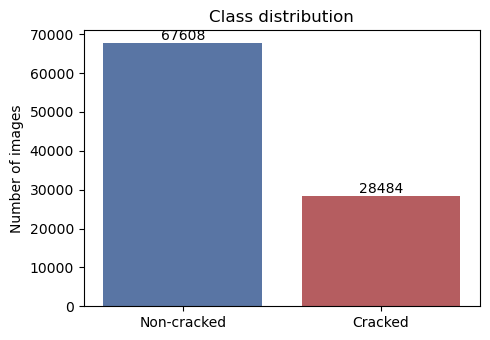

In [7]:
fig, ax = plt.subplots(figsize=(5, 3.5))
sns.barplot(x=[CLASS_NAMES[i] for i in counts.index], y=counts.values, ax=ax, palette=["#4C72B0", "#C44E52"])
for i, v in enumerate(counts.values):
    ax.text(i, v, str(v), ha="center", va="bottom")
ax.set_title("Class distribution"); ax.set_ylabel("Number of images")
plt.tight_layout(); plt.savefig("plots/class_distribution.png", dpi=150); plt.show()

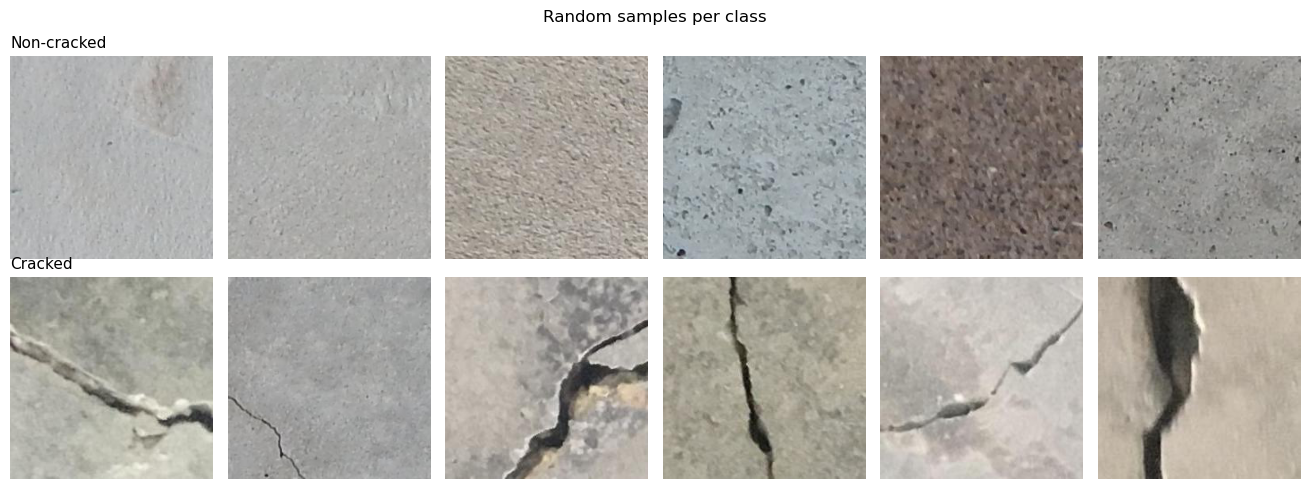

In [8]:
def show_samples(n=6):
    fig, axes = plt.subplots(2, n, figsize=(2.2*n, 5))
    for r, lab in enumerate([0, 1]):
        picks = df[df.label == lab].sample(n, random_state=SEED)
        for c, p in enumerate(picks["path"]):
            axes[r, c].imshow(Image.open(os.path.join(DATA_ROOT, p)).convert("RGB"))
            axes[r, c].axis("off")
            if c == 0: axes[r, c].set_title(CLASS_NAMES[lab], loc="left", fontsize=11)
    plt.suptitle("Random samples per class"); plt.tight_layout()
    plt.savefig("plots/samples.png", dpi=150); plt.show()
show_samples()

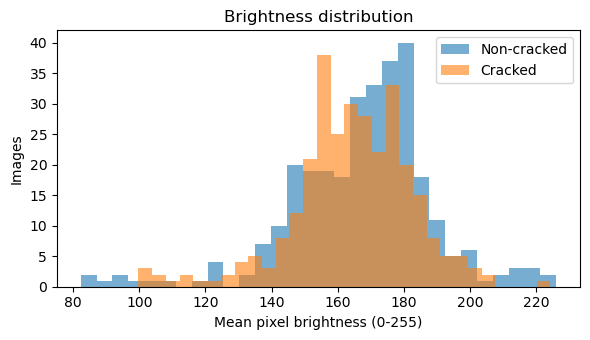

In [9]:
# Mean brightness per image (grayscale) for 300 random images per class
def mean_brightness(p):
    return np.asarray(Image.open(os.path.join(DATA_ROOT, p)).convert("L")).mean()

plt.figure(figsize=(6, 3.5))
for lab in [0, 1]:
    s = df[df.label == lab].sample(min(300, (df.label == lab).sum()), random_state=SEED)
    plt.hist([mean_brightness(p) for p in s["path"]], bins=30, alpha=0.6, label=CLASS_NAMES[lab])
plt.xlabel("Mean pixel brightness (0-255)"); plt.ylabel("Images"); plt.legend()
plt.title("Brightness distribution"); plt.tight_layout()
plt.savefig("plots/brightness.png", dpi=150); plt.show()

## 6. Train / validation / test split (70 / 15 / 15)

- **Stratified**: each split keeps the same class ratio.
- Fixed seed, and the split is **saved to `split.csv`**. Send this file to your teammates so everybody evaluates on the *exact same* test images.
- The **validation** set is used to pick the best epoch and to do early stopping. The **test** set is only used for the final numbers.

In [10]:
if os.path.exists("split.csv") and not FORCE_RETRAIN:
    df = pd.read_csv("split.csv")                 # reuse the team's shared split
    print("Loaded existing split.csv")
else:
    train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df["label"], random_state=SEED)
    val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["label"], random_state=SEED)
    train_df = train_df.assign(split="train"); val_df = val_df.assign(split="val"); test_df = test_df.assign(split="test")
    df = pd.concat([train_df, val_df, test_df]).reset_index(drop=True)
    df.to_csv("split.csv", index=False)
    print("Saved split.csv")

print(df.groupby(["split", "label"]).size().unstack().rename(columns=dict(enumerate(CLASS_NAMES))))

Loaded existing split.csv
label  Non-cracked  Cracked
split                      
test         10142     4272
train        47325    19939
val          10141     4273


## 7. Datasets, transforms and data loaders

- **Training transform:** resize + random flips/rotation/brightness jitter. Augmentation makes the model see slightly different images every epoch, which reduces overfitting. (Cracks stay cracks when flipped.)
- **Eval transform:** only resize + normalize (no randomness), so results are reproducible.
- **Normalization** with the ImageNet mean/std is required because ResNet50 was trained that way.
- `train_eval_ds` is the training set *without* augmentation; it is used to measure the "train accuracy" fairly.

In [11]:
train_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

class CrackDataset(Dataset):
    def __init__(self, frame, transform):
        self.paths = frame["path"].tolist()
        self.labels = frame["label"].tolist()
        self.transform = transform
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(os.path.join(DATA_ROOT, self.paths[i])).convert("RGB")  # force 3 channels
        return self.transform(img), self.labels[i]

train_df = df[df.split == "train"]; val_df = df[df.split == "val"]; test_df = df[df.split == "test"]
EXP_TRAIN = 8000      # training images used for the comparison runs; None = use all
if EXP_TRAIN:
    train_df = (train_df.groupby("label", group_keys=False)
                .apply(lambda g: g.sample(min(len(g), EXP_TRAIN // 2), random_state=SEED)))
    val_df = val_df.sample(min(len(val_df), 3000), random_state=SEED)
train_ds      = CrackDataset(train_df, train_tf)
train_eval_ds = CrackDataset(train_df, eval_tf)
val_ds        = CrackDataset(val_df, eval_tf)
test_ds       = CrackDataset(test_df, eval_tf)

def make_loader(ds, batch_size, shuffle=False):
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle,
                      num_workers=NUM_WORKERS, pin_memory=(device == "cuda"))

# Class weights (higher weight for the rarer class) so the loss isn't dominated by the majority class
cnt = train_df["label"].value_counts().sort_index().values
CLASS_WEIGHTS = torch.tensor(cnt.sum() / (2.0 * cnt), dtype=torch.float32)
print("Class weights:", CLASS_WEIGHTS.tolist())

Class weights: [1.0, 1.0]


C:\Users\COMPUMARTS\AppData\Local\Temp\ipykernel_16044\365279256.py:31: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(min(len(g), EXP_TRAIN // 2), random_state=SEED)))


# Part II: The model (ResNet50 transfer learning)

## 8. Building the model

- Load ResNet50 with ImageNet weights.
- **Freezing** a layer (`requires_grad=False`) means its weights are not updated. Early layers learn generic features (edges, textures), so freezing them is safe and saves memory and time.
- `unfreeze` controls how many blocks are trained: `"head"` (only the new classifier), `"layer4"` (last block + head), `"layer3_4"` (last two blocks + head). This is our **"number of layers"** hyperparameter.
- `head` controls the classifier: `"1fc"` (one Linear layer) or `"2fc"` (two Linear layers). This is the second **"number of layers"** variation.
- `dropout` randomly zeroes activations during training to fight overfitting.

In [12]:
def build_model(unfreeze="layer4", head="1fc", dropout=0.3, pretrained=True):
    weights = models.ResNet50_Weights.IMAGENET1K_V2 if pretrained else None
    m = models.resnet50(weights=weights)

    for p in m.parameters():                      # 1) freeze everything
        p.requires_grad = False
    blocks = {"head": [], "layer4": [m.layer4], "layer3_4": [m.layer3, m.layer4]}[unfreeze]
    for b in blocks:                              # 2) unfreeze the chosen blocks
        for p in b.parameters():
            p.requires_grad = True

    in_f = m.fc.in_features                       # 2048 for ResNet50
    if head == "1fc":
        m.fc = nn.Sequential(nn.Dropout(dropout), nn.Linear(in_f, 2))
    else:  # "2fc"
        m.fc = nn.Sequential(nn.Linear(in_f, 256), nn.ReLU(), nn.Dropout(dropout), nn.Linear(256, 2))
    return m.to(device)   # the new head is created trainable by default

m = build_model()
trainable = sum(p.numel() for p in m.parameters() if p.requires_grad)
total = sum(p.numel() for p in m.parameters())
print(f"Trainable parameters: {trainable:,} / {total:,}")
del m

Trainable parameters: 14,968,834 / 23,512,130


## 9. `training()` and `evaluation()` functions

**`training(...)`**
- Builds the optimizer (SGD / Adam / RMSprop) with `weight_decay` (L2 regularization) and a learning-rate scheduler (`none`, `step`, `cosine`).
- Uses **mixed precision (AMP)**: runs most math in float16, which is faster and uses much less VRAM. Important for a 4 GB GPU.
- Keeps frozen BatchNorm layers in eval mode so their ImageNet statistics are not corrupted.
- After every epoch it measures validation loss/accuracy, **saves the checkpoint if validation loss improved**, and applies **early stopping** (stops after `patience` epochs with no improvement). This is how we avoid overfitting automatically.

**`evaluation(ckpt_path, loader)`** loads a saved model from disk and returns its loss/accuracy on any loader, as the assignment asks.

In [13]:
@torch.no_grad()
def run_eval(model, loader, criterion=None):
    # Returns loss, accuracy, predictions and true labels for one pass over `loader`
    model.eval()
    tot_loss, preds, labels = 0.0, [], []
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        out = model(x)   # full float32 precision for evaluation (avoids float16 overflow -> nan)
        if criterion is not None:
            tot_loss += criterion(out, y).item() * y.size(0)
        preds.append(out.argmax(1).cpu()); labels.append(y.cpu())
    preds, labels = torch.cat(preds).numpy(), torch.cat(labels).numpy()
    return tot_loss / len(labels), (preds == labels).mean(), preds, labels


def set_train_mode(model):
    model.train()
    for mod in model.modules():   # frozen BatchNorm layers stay in eval mode
        if isinstance(mod, nn.BatchNorm2d) and not any(p.requires_grad for p in mod.parameters()):
            mod.eval()


def make_optimizer(params, name, lr, weight_decay):
    if name == "adam":    return torch.optim.Adam(params, lr=lr, weight_decay=weight_decay)
    if name == "sgd":     return torch.optim.SGD(params, lr=lr, momentum=0.9, weight_decay=weight_decay)
    if name == "rmsprop": return torch.optim.RMSprop(params, lr=lr, weight_decay=weight_decay)
    raise ValueError(name)


def make_scheduler(opt, name, epochs):
    if name == "step":   return torch.optim.lr_scheduler.StepLR(opt, step_size=max(1, epochs // 3), gamma=0.1)
    if name == "cosine": return torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    return None


def training(model, train_loader, val_loader, cfg, ckpt_path):
    params = [p for p in model.parameters() if p.requires_grad]       # only trainable weights
    opt = make_optimizer(params, cfg["optimizer"], cfg["lr"], cfg["weight_decay"])
    sched = make_scheduler(opt, cfg["scheduler"], cfg["epochs"])
    weight = CLASS_WEIGHTS.to(device) if cfg["class_weight"] else None
    criterion = nn.CrossEntropyLoss(weight=weight)
    scaler = torch.amp.GradScaler(enabled=(device == "cuda"))          # needed for float16 training

    hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [], "lr": []}
    best_val_loss, best_epoch, bad_epochs = float("inf"), -1, 0

    for ep in range(cfg["epochs"]):
        t0 = time.time()
        set_train_mode(model)
        run_loss, correct, n = 0.0, 0, 0
        for x, y in tqdm(train_loader, desc=f"epoch {ep+1}/{cfg['epochs']}", leave=False):
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device, enabled=(device == "cuda")):
                out = model(x)
            loss = criterion(out.float(), y)
            scaler.scale(loss).backward()      # backprop with loss scaling
            scaler.step(opt); scaler.update()  # update weights
            run_loss += loss.item() * y.size(0); correct += (out.argmax(1) == y).sum().item(); n += y.size(0)
        hist["lr"].append(opt.param_groups[0]["lr"])
        if sched: sched.step()

        val_loss, val_acc, _, _ = run_eval(model, val_loader, criterion)
        hist["train_loss"].append(run_loss / n); hist["train_acc"].append(correct / n)
        hist["val_loss"].append(float(val_loss)); hist["val_acc"].append(float(val_acc))
        print(f"epoch {ep+1:2d} | train loss {run_loss/n:.4f} acc {correct/n:.4f} | "
              f"val loss {val_loss:.4f} acc {val_acc:.4f} | {time.time()-t0:.0f}s")

        # Save a checkpoint after epoch 1 no matter what, then only when validation loss improves.
        # A nan/inf loss never counts as an improvement, and can no longer leave us without a checkpoint.
        improved = np.isfinite(val_loss) and val_loss < best_val_loss - 1e-4
        if best_epoch == -1 or improved:
            if np.isfinite(val_loss):
                best_val_loss = val_loss
            best_epoch, bad_epochs = ep + 1, 0
            torch.save({"state_dict": model.state_dict(), "cfg": cfg}, ckpt_path)
        else:                                  # no improvement -> count towards early stopping
            bad_epochs += 1
            if bad_epochs >= cfg["patience"]:
                print(f"Early stopping at epoch {ep+1} (best epoch = {best_epoch})")
                break
    hist["best_epoch"] = best_epoch
    return hist


def load_model(ckpt_path):
    # Rebuilds the architecture from the saved config and loads the weights. pretrained=False => no download needed.
    ck = torch.load(ckpt_path, map_location=device, weights_only=False)
    c = ck["cfg"]
    model = build_model(c["unfreeze"], c["head"], c["dropout"], pretrained=False)
    model.load_state_dict(ck["state_dict"])
    return model, c


def evaluation(ckpt_path, loader):
    # Loads a trained model from disk and evaluates it on `loader`
    model, _ = load_model(ckpt_path)
    loss, acc, preds, labels = run_eval(model, loader, nn.CrossEntropyLoss())
    return acc, preds, labels

## 10. Experiment runner (with result caching)

`BASE` is the default configuration. Each experiment changes **one** hyperparameter and leaves the others at the base value (as the assignment suggests).

`run_experiment` does: train (or load saved result) -> evaluate best checkpoint on train/val/test -> save `results/<name>.json`.
**If the json already exists, nothing is retrained.**

- `epochs` is a maximum; early stopping usually ends sooner.
- Checkpoints (`.pt`, about 95 MB each) are optional for sharing; only the json files are needed to rebuild all tables and plots.

In [14]:
BASE = dict(
    unfreeze="layer4", head="1fc", dropout=0.3,
    optimizer="adam", lr=1e-4, weight_decay=1e-4, scheduler="cosine",
    batch_size=32, epochs=6, patience=2, class_weight=True,
)

def exp_name(overrides):
    diff = {k: v for k, v in overrides.items() if BASE[k] != v}
    return "baseline" if not diff else "_".join(f"{k}-{v}" for k, v in diff.items())

def run_experiment(group, **overrides):
    cfg = {**BASE, **overrides}
    name = exp_name(overrides)
    json_path, ckpt_path = f"results/{name}.json", f"results/{name}.pt"

    if os.path.exists(json_path) and not FORCE_RETRAIN:           # already done -> reuse
        print(f"[cached] {name}")
        return json.load(open(json_path))

    print(f"\n=== {name} ===")
    set_seed()
    try:
        model = build_model(cfg["unfreeze"], cfg["head"], cfg["dropout"])
        train_loader = make_loader(train_ds, cfg["batch_size"], shuffle=True)
        val_loader = make_loader(val_ds, cfg["batch_size"])
        t0 = time.time()
        hist = training(model, train_loader, val_loader, cfg, ckpt_path)
        minutes = (time.time() - t0) / 60
    except torch.cuda.OutOfMemoryError:
        print("Out of GPU memory: use a smaller batch_size or unfreeze fewer layers.")
        torch.cuda.empty_cache()
        return None
    del model; torch.cuda.empty_cache()

    # Evaluate the BEST saved checkpoint (loaded from disk) on train / val / test
    bs = 64
    tr_acc, _, _ = evaluation(ckpt_path, make_loader(train_eval_ds, bs))
    va_acc, _, _ = evaluation(ckpt_path, make_loader(val_ds, bs))
    te_acc, _, _ = evaluation(ckpt_path, make_loader(test_ds, bs))
    res = dict(name=name, group=group, cfg=cfg, history=hist, minutes=round(minutes, 1),
               train_acc=float(tr_acc), val_acc=float(va_acc), test_acc=float(te_acc))
    json.dump(res, open(json_path, "w"), indent=1)
    print(f"-> train {tr_acc:.4f} | val {va_acc:.4f} | test {te_acc:.4f} | {minutes:.1f} min")
    return res

def plot_history(res, save=True):
    h = res["history"]; ep = range(1, len(h["train_loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    ax[0].plot(ep, h["train_acc"], "o-", label="train"); ax[0].plot(ep, h["val_acc"], "o-", label="validation")
    ax[0].axvline(h["best_epoch"], ls="--", c="gray", label="best epoch")
    ax[0].set_title(f"Accuracy: {res['name']}"); ax[0].set_xlabel("epoch"); ax[0].legend()
    ax[1].plot(ep, h["train_loss"], "o-", label="train"); ax[1].plot(ep, h["val_loss"], "o-", label="validation")
    ax[1].axvline(h["best_epoch"], ls="--", c="gray")
    ax[1].set_title("Loss"); ax[1].set_xlabel("epoch"); ax[1].legend()
    plt.tight_layout()
    if save: plt.savefig(f"plots/curves_{res['name']}.png", dpi=130)
    plt.show()

In [15]:
import time
print("NUM_WORKERS =", NUM_WORKERS, "| train images:", len(train_ds), flush=True)

# 1) Read ONE image from disk
t0 = time.time()
img = Image.open(os.path.join(DATA_ROOT, train_ds.paths[0])); img.load()
print("1) read 1 image:", img.size, round(time.time()-t0, 2), "s", flush=True)

# 2) Read 20 images with the transforms
t0 = time.time()
for i in range(20): train_ds[i]
print("2) 20 images with transforms:", round(time.time()-t0, 1), "s", flush=True)

# 3) First GPU operation
t0 = time.time()
a = torch.randn(1000, 1000, device=device); torch.cuda.synchronize()
print("3) first GPU op:", round(time.time()-t0, 1), "s", flush=True)

# 4) Build the model
t0 = time.time()
m = build_model("layer4", "1fc", 0.3)
print("4) build model:", round(time.time()-t0, 1), "s", flush=True)

# 5) One forward pass on 8 images
xb = torch.stack([train_ds[i][0] for i in range(8)]).to(device)
t0 = time.time()
with torch.no_grad(), torch.autocast(device_type="cuda"):
    m(xb)
torch.cuda.synchronize()
print("5) forward 8 images:", round(time.time()-t0, 1), "s", flush=True)
del m

NUM_WORKERS = 0 | train images: 8000
1) read 1 image: (256, 256) 0.0 s
2) 20 images with transforms: 0.1 s
3) first GPU op: 0.1 s
4) build model: 0.6 s
5) forward 8 images: 0.7 s


In [16]:
import time
m = build_model("layer4", "1fc", 0.3)
loader = make_loader(train_ds, 32, shuffle=True)
print("NUM_WORKERS =", NUM_WORKERS, "| batches per epoch:", len(loader), flush=True)
t0 = time.time()
for i, (x, y) in enumerate(loader):
    x, y = x.to(device), y.to(device)
    with torch.autocast(device_type="cuda"):
        out = m(x)
    out.float().sum().backward()
    torch.cuda.synchronize()
    print(f"batch {i}: {time.time()-t0:.2f}s", flush=True)
    t0 = time.time()
    if i == 4: break
del m

NUM_WORKERS = 0 | batches per epoch: 250
batch 0: 1.33s
batch 1: 1.19s
batch 2: 1.16s
batch 3: 1.17s
batch 4: 1.16s


## 11. Baseline run

Run this first. It tells you how long one epoch takes on your GPU, so you can estimate the full study. Watch the gap between train and validation accuracy: when validation loss stops improving while train accuracy keeps rising, the model is starting to overfit (early stopping handles it for you).

[cached] baseline


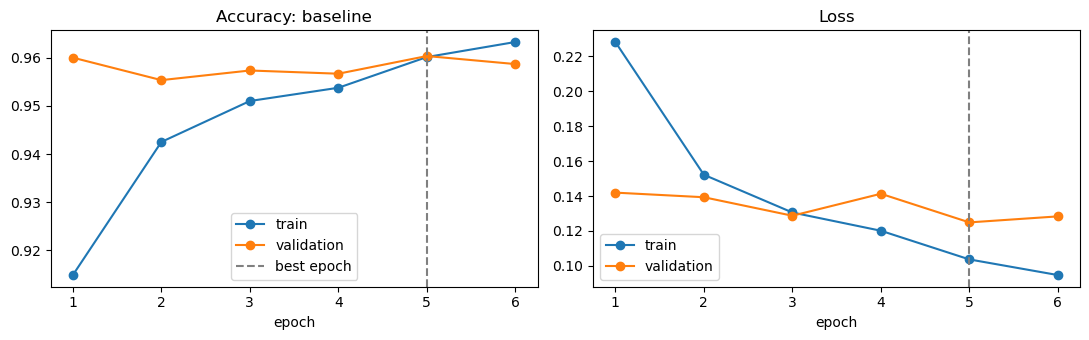

In [17]:
baseline = run_experiment("baseline")
plot_history(baseline)

## 12. Hyperparameter study (one at a time)

Each group changes a single hyperparameter. Values equal to the baseline reuse the baseline result (no extra training).

| Group | Values |
|---|---|
| Batch size | 16, 32, 64 |
| Number of layers (unfrozen blocks) | head only, layer4, layer3+4 |
| Number of layers (classifier head) | 1 FC, 2 FC |
| Dropout | 0.0, 0.3, 0.5 |
| Optimizer | SGD(momentum 0.9), Adam, RMSprop |
| Weight decay (L2) | 0, 1e-4, 1e-3 |
| Learning rate | 1e-3, 1e-4, 1e-5 |
| LR scheduler | none, step, cosine |

You can run one group per cell/session, since the results are cached. If your GPU runs out of memory, skip `batch_size=64` or `layer3_4`.

In [18]:
GROUPS = {
    "batch_size":   [dict(batch_size=b) for b in (16, 32, 64)],
    "unfreeze":     [dict(unfreeze=u) for u in ("head", "layer4", "layer3_4")],
    "head":         [dict(head=h) for h in ("1fc", "2fc")],
    "dropout":      [dict(dropout=d) for d in (0.0, 0.3, 0.5)],
    "optimizer":    [dict(optimizer="sgd", lr=1e-3), dict(optimizer="adam"), dict(optimizer="rmsprop")],
    "weight_decay": [dict(weight_decay=w) for w in (0.0, 1e-4, 1e-3)],
    "lr":           [dict(lr=l) for l in (1e-3, 1e-4, 1e-5)],
    "scheduler":    [dict(scheduler=s) for s in ("none", "step", "cosine")],
}
# Note: SGD uses lr=1e-3 because SGD with 1e-4 learns very slowly; mention this in your report.

In [19]:
all_results = {}
for group, variants in GROUPS.items():
    for ov in variants:
        res = run_experiment(group, **ov)
        if res: all_results[res["name"]] = res

[cached] batch_size-16
[cached] baseline
[cached] batch_size-64
[cached] unfreeze-head
[cached] baseline
[cached] unfreeze-layer3_4
[cached] baseline
[cached] head-2fc
[cached] dropout-0.0
[cached] baseline
[cached] dropout-0.5
[cached] optimizer-sgd_lr-0.001
[cached] baseline
[cached] optimizer-rmsprop
[cached] weight_decay-0.0
[cached] baseline
[cached] weight_decay-0.001
[cached] lr-0.001
[cached] baseline
[cached] lr-1e-05
[cached] scheduler-none
[cached] scheduler-step
[cached] baseline


## 13. Results table and comparison plots

In [20]:
# Rebuild everything from the saved json files (works even if no model was trained in this session)
all_results = {}
for f in sorted(os.listdir("results")):
    if f.endswith(".json"):
        r = json.load(open(f"results/{f}")); all_results[r["name"]] = r

table = pd.DataFrame([{
    "experiment": r["name"], "group": r["group"],
    "train_acc": round(r["train_acc"], 4), "val_acc": round(r["val_acc"], 4), "test_acc": round(r["test_acc"], 4),
    "best_epoch": r["history"]["best_epoch"], "epochs_run": len(r["history"]["train_loss"]), "minutes": r["minutes"],
} for r in all_results.values()]).sort_values(["group", "experiment"])
table.to_csv("results_table.csv", index=False)
table

,experiment,group,train_acc,val_acc,test_acc,best_epoch,epochs_run,minutes
0,baseline,baseline,0.9704,0.9603,0.9584,5,6,34.0
1,batch_size-16,batch_size,0.9708,0.9597,0.9580,5,6,35.9
2,batch_size-64,batch_size,0.9702,0.9577,0.9548,6,6,32.8
3,dropout-0.0,dropout,0.9715,0.9580,0.9573,5,6,33.7
4,dropout-0.5,dropout,0.9705,0.9580,0.9567,5,6,33.7
5,head-2fc,head,0.9634,0.9617,0.9595,3,5,28.2
6,lr-0.001,lr,0.9610,0.9627,0.9611,5,6,34.1
7,lr-1e-05,lr,0.9413,0.9503,0.9495,5,6,33.9
8,optimizer-rmsprop,optimizer,0.9692,0.9600,0.9596,5,6,33.7
9,optimizer-sgd_lr-0.001,optimizer,0.9411,0.9467,0.9466,5,6,33.6


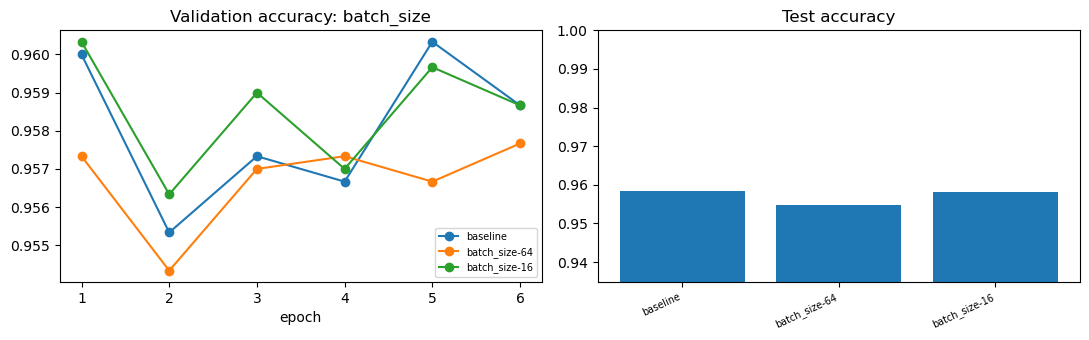

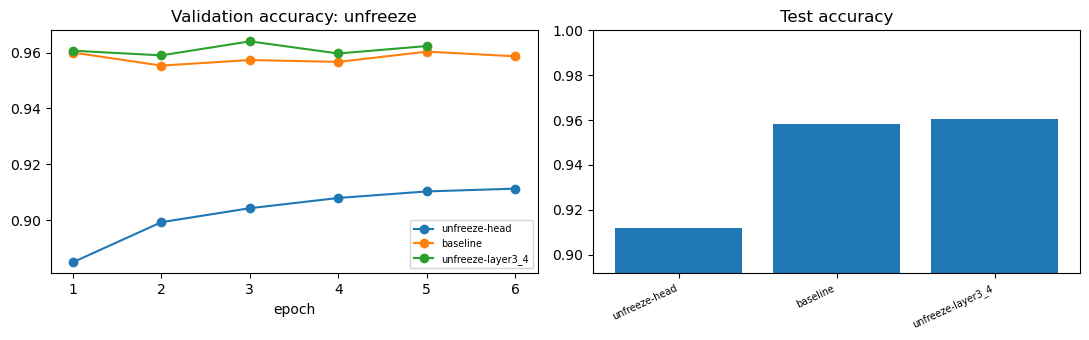

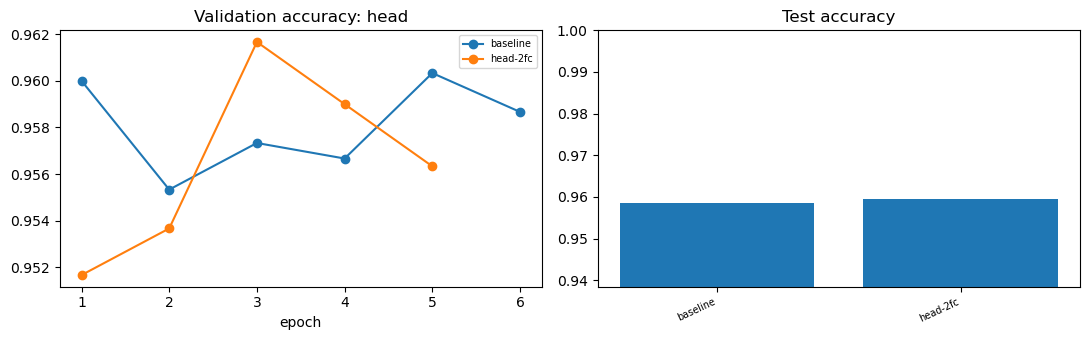

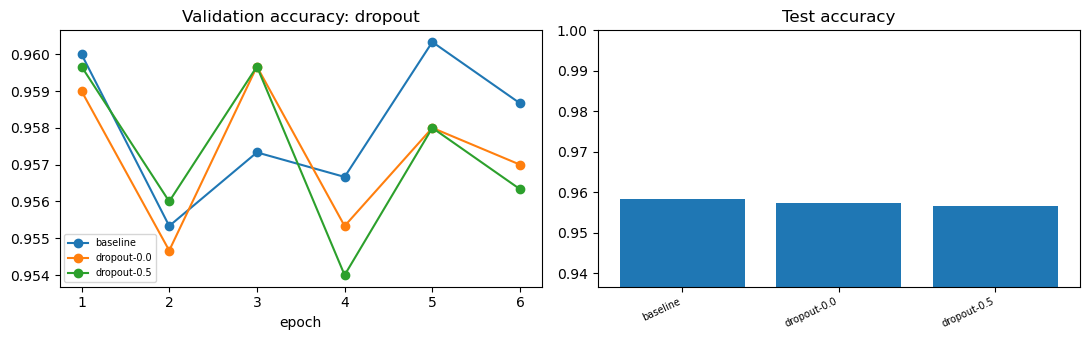

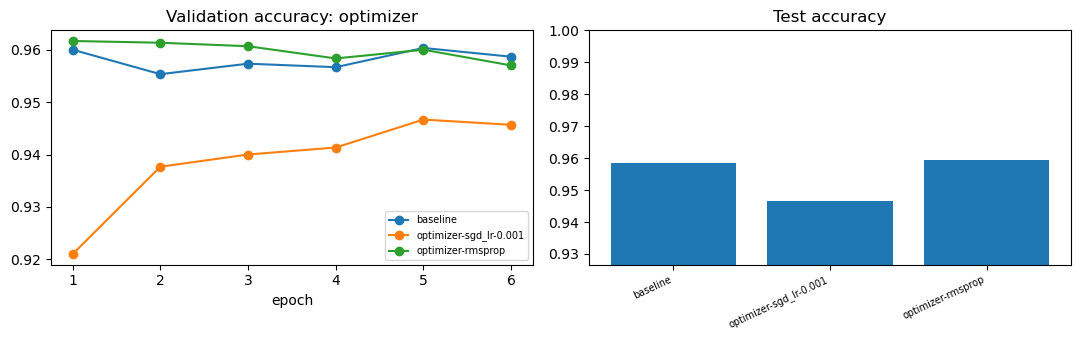

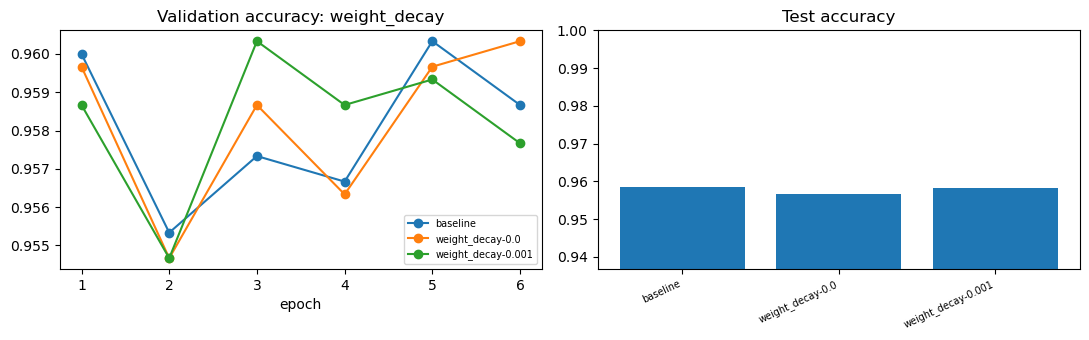

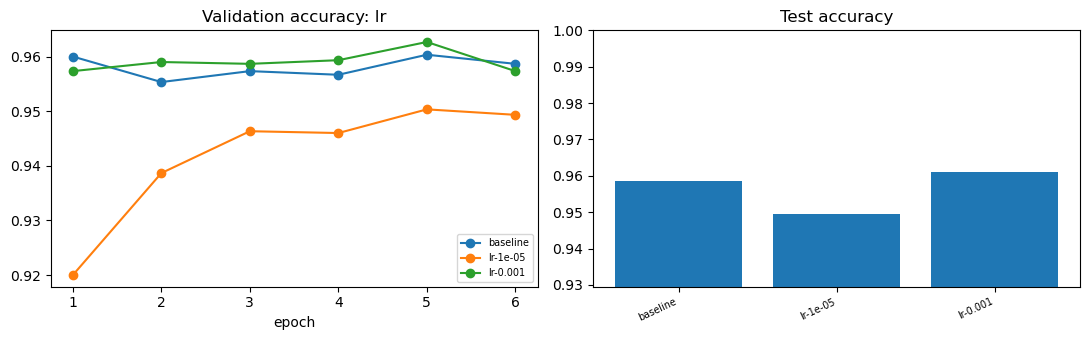

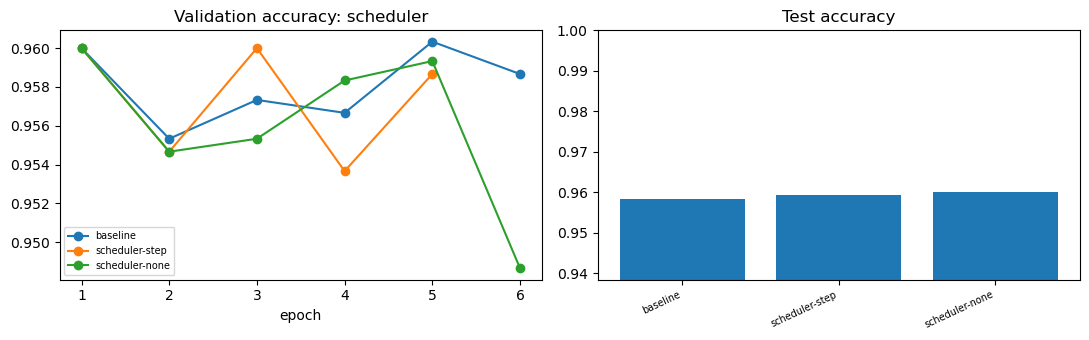

In [21]:
# One plot per hyperparameter group: validation accuracy curves + final test accuracy
for group in GROUPS:
    runs = [r for r in all_results.values() if r["group"] == group or r["name"] == "baseline"]
    # runs of this group (the baseline is the shared reference)
    names = {exp_name(ov) for ov in GROUPS[group]}
    runs = [all_results[n] for n in names if n in all_results]
    if not runs: continue
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    for r in runs:
        ax[0].plot(range(1, len(r["history"]["val_acc"]) + 1), r["history"]["val_acc"], "o-", label=r["name"])
    ax[0].set_title(f"Validation accuracy: {group}"); ax[0].set_xlabel("epoch"); ax[0].legend(fontsize=7)
    ax[1].bar([r["name"] for r in runs], [r["test_acc"] for r in runs])
    lo = min(r["test_acc"] for r in runs); ax[1].set_ylim(max(0, lo - 0.02), 1.0)
    ax[1].set_title("Test accuracy"); plt.setp(ax[1].get_xticklabels(), rotation=25, ha="right", fontsize=7)
    plt.tight_layout(); plt.savefig(f"plots/group_{group}.png", dpi=130); plt.show()

## 14. Pick and save the final model

We choose the experiment with the highest **validation** accuracy (not test, to avoid "peeking" at the test set), copy its checkpoint to `final_model/resnet50_best.pt`, and evaluate it on the test set.

In [22]:
import shutil
best_name = max(all_results, key=lambda n: (all_results[n]["val_acc"], -all_results[n]["history"]["best_epoch"]))
print("Best experiment by validation accuracy:", best_name, "| val acc:", all_results[best_name]["val_acc"])

if os.path.exists(f"results/{best_name}.pt"):
    shutil.copy(f"results/{best_name}.pt", "final_model/resnet50_best.pt")
json.dump(all_results[best_name], open("final_model/best_config_and_history.json", "w"), indent=1)
print("Saved final_model/resnet50_best.pt")

Best experiment by validation accuracy: unfreeze-layer3_4 | val acc: 0.964
Saved final_model/resnet50_best.pt


## 15. Load the trained model and evaluate (NO training needed)

**This is the section for anyone who downloaded the notebook.** It requires only:
1. `final_model/resnet50_best.pt` (and optionally the `results/*.json` files)
2. `split.csv` (so the test set is identical)
3. Running sections 1, 2, 3, 7, 8, 9 to define the functions and data, then this section.

Nothing here trains anything.

Train accuracy: 0.9646
Test accuracy : 0.9605

              precision    recall  f1-score   support

 Non-cracked     0.9682    0.9759    0.9721     10142
     Cracked     0.9418    0.9239    0.9328      4272

    accuracy                         0.9605     14414
   macro avg     0.9550    0.9499    0.9524     14414
weighted avg     0.9604    0.9605    0.9604     14414



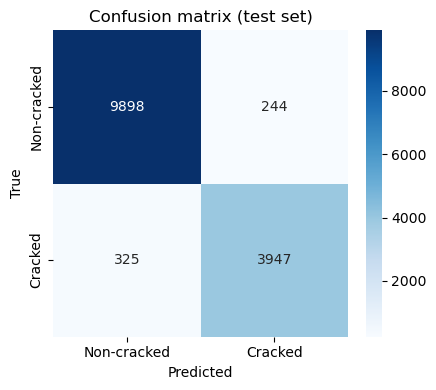

In [23]:
final_ckpt = "final_model/resnet50_best.pt"
test_loader = make_loader(test_ds, 64)

test_acc, preds, labels = evaluation(final_ckpt, test_loader)
train_acc, _, _ = evaluation(final_ckpt, make_loader(train_eval_ds, 64))
print(f"Train accuracy: {train_acc:.4f}")
print(f"Test accuracy : {test_acc:.4f}\n")
print(classification_report(labels, preds, target_names=CLASS_NAMES, digits=4))

cm = confusion_matrix(labels, preds)
plt.figure(figsize=(4.5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Confusion matrix (test set)")
plt.tight_layout(); plt.savefig("plots/confusion_matrix.png", dpi=150); plt.show()

569 misclassified out of 14414 test images


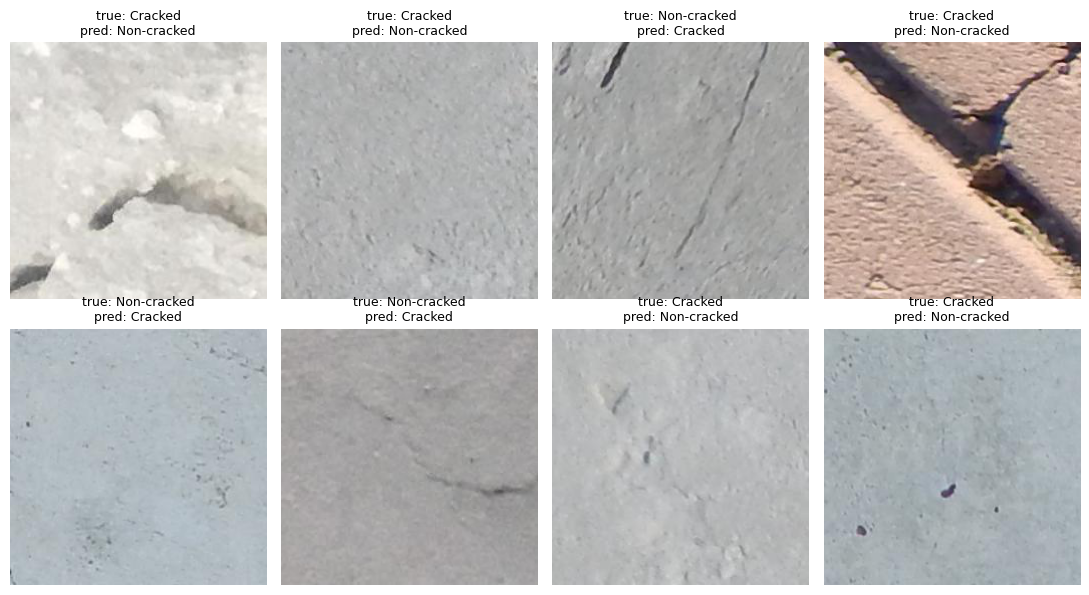

In [24]:
# Show some misclassified test images (useful for the analysis section of the report)
wrong = np.where(preds != labels)[0]
print(f"{len(wrong)} misclassified out of {len(labels)} test images")
pick = wrong[:8]
if len(pick):
    fig, axes = plt.subplots(2, 4, figsize=(11, 6))
    for ax, i in zip(axes.ravel(), pick):
        ax.imshow(Image.open(os.path.join(DATA_ROOT, test_ds.paths[i])).convert("RGB"))
        ax.set_title(f"true: {CLASS_NAMES[labels[i]]}\npred: {CLASS_NAMES[preds[i]]}", fontsize=9); ax.axis("off")
    plt.tight_layout(); plt.savefig("plots/misclassified.png", dpi=150); plt.show()

## 16. Package everything to share with the team

Creates `share_bundle.zip` containing only what others need (final model, results json files, tables, plots, `split.csv`). The per-experiment `.pt` checkpoints are left out to keep the file small (about 100 MB instead of over 1 GB).

In [25]:
import zipfile
with zipfile.ZipFile("share_bundle.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for f in ["split.csv", "results_table.csv"]:
        if os.path.exists(f): z.write(f)
    for folder, only_ext in [("final_model", None), ("plots", None), ("results", ".json")]:
        for f in os.listdir(folder):
            if only_ext is None or f.endswith(only_ext):
                z.write(os.path.join(folder, f))
print("Created share_bundle.zip:", round(os.path.getsize("share_bundle.zip")/1e6, 1), "MB")

# On Colab, to download it:  from google.colab import files; files.download("share_bundle.zip")

Created share_bundle.zip: 90.5 MB
